## Imports

In [ ]:
!pip install repseq


In [ ]:
%pip install logomaker

In [ ]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

## WORKING DIR

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
import os

PROJECT_ROOT = Path('/content/drive/MyDrive/Colab Notebooks/ImmuneSem')

WORKING_DIR = str(PROJECT_ROOT / 'outputs' / 'repseq')

os.makedirs(WORKING_DIR, exist_ok=True)

print("Проект найден:", PROJECT_ROOT.exists())
print("Данные найдены:", (PROJECT_ROOT / 'data').exists())
print("Папка результатов:", WORKING_DIR)

Проект найден: True
Данные найдены: True
Папка результатов: /content/drive/MyDrive/Colab Notebooks/ImmuneSem/outputs/repseq


## Read clonosets

In [ ]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")


In [ ]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False,
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,c5_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
1,UCB5_nCD4_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
2,UCB3_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
3,UCB2_nCD4_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
4,UCB6_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
...,...,...,...
82,UCB5_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
83,a5_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
84,a3_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...
85,o6_nTreg_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...


## Create metadata

In [ ]:
# Задаём порядок экспериментальных групп и клеточных популяций для графиков.
# # Затем читаем метаданные и добавляем источник материала: UCB или PB.
# Define the custom ordered type
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
# metadata["sample_id"] = metadata["sample_id"].apply(lambda x: x.split("_TRB")[0])
metadata.tail()

,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


## Subset clonosets

In [ ]:
# Объединяем пути к клоносетам с метаданными по общим столбцам и оставляем nCD4
clonosets_cd8 = clonosets.merge(metadata).query("subset == 'nCD8'").reset_index(drop=True)
clonosets_cd8

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,UCB3_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB3,nCD8,UCB
1,UCB11_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB11,nCD8,UCB
2,c4_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,children,c4,nCD8,PB
3,UCB13_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB13,nCD8,UCB
4,UCB12_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB12,nCD8,UCB
5,o1_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,older_adults,o1,nCD8,PB
6,UCB4_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB4,nCD8,UCB
7,UCB10_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,term,UCB10,nCD8,UCB
8,c1_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,children,c1,nCD8,PB
9,a6_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,adults,a6,nCD8,PB


## Have a look at clonosets contents

In [ ]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_cd8 = stats.calc_clonoset_stats(clonosets_cd8, cpu=2)
clonoset_stats_cd8

Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,UCB3_nCD8_TRB_1,TRB,54212,50909,31675,19234,3303,0.060927,85420,81816,3604,0.042192,NaN,NaN,NaN,NaN,NaN
1,UCB11_nCD8_TRB_1,TRB,69412,66274,29398,36876,3138,0.045208,148419,144769,3650,0.024593,NaN,NaN,NaN,NaN,NaN
2,c4_nCD8_TRB_1,TRB,37919,36571,26478,10093,1348,0.035549,53145,51597,1548,0.029128,NaN,NaN,NaN,NaN,NaN
3,UCB13_nCD8_TRB_1,TRB,42841,41255,32843,8412,1586,0.037021,55050,53362,1688,0.030663,NaN,NaN,NaN,NaN,NaN
4,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN
5,o1_nCD8_TRB_1,TRB,35822,33909,25252,8657,1913,0.053403,49604,47469,2135,0.043041,NaN,NaN,NaN,NaN,NaN
6,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN
7,UCB10_nCD8_TRB_1,TRB,87324,83632,48497,35135,3692,0.042279,145678,141490,4188,0.028748,NaN,NaN,NaN,NaN,NaN
8,c1_nCD8_TRB_1,TRB,47503,45987,32249,13738,1516,0.031914,68155,66536,1619,0.023755,NaN,NaN,NaN,NaN,NaN
9,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN


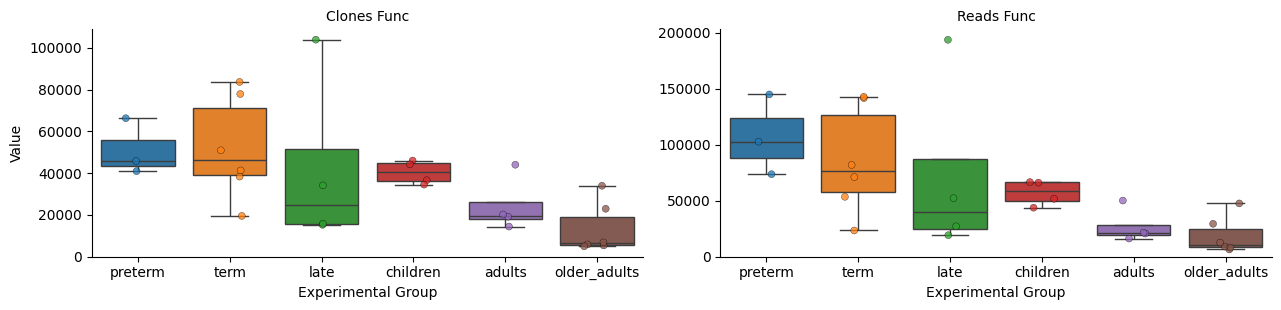

In [ ]:
# Сравниваем объём функциональной части репертуаров между экспериментальными группами.
rsplot.clonoset_stats(clonoset_stats_cd8, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [ ]:
# Сортируем образцы по числу функциональных наблюдений: это помогает выбрать downsample.
clonoset_stats_cd8.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
11,o7_nCD8_TRB_1,TRB,5972,5823,5515,308,149,0.024950,6522,6368,154,0.023612,NaN,NaN,NaN,NaN,NaN
20,o2_nCD8_TRB_1,TRB,7077,6818,6027,791,259,0.036597,8325,8056,269,0.032312,NaN,NaN,NaN,NaN,NaN
14,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
24,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
26,a5_nCD8_TRB_1,TRB,15111,14377,12881,1496,734,0.048574,16879,16091,788,0.046685,NaN,NaN,NaN,NaN,NaN
12,UCB7_nCD8_TRB_1,TRB,16440,15764,13016,2748,676,0.041119,19808,19100,708,0.035743,NaN,NaN,NaN,NaN,NaN
9,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
15,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
4,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN
6,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN


In [ ]:
depths = clonoset_stats_cd8["reads_func"]

print(depths.describe())

count        27.000000
mean      58324.111111
std       48931.496336
min        6368.000000
25%       20973.000000
50%       50019.000000
75%       72269.500000
max      193529.000000
Name: reads_func, dtype: float64


In [ ]:
clonoset_stats_cd8.merge(metadata).groupby("experimental_group").size()

/tmp/ipykernel_2196/171168448.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clonoset_stats_cd8.merge(metadata).groupby("experimental_group").size()


,0
experimental_group,
preterm,3
term,6
late,4
children,4
adults,4
older_adults,6


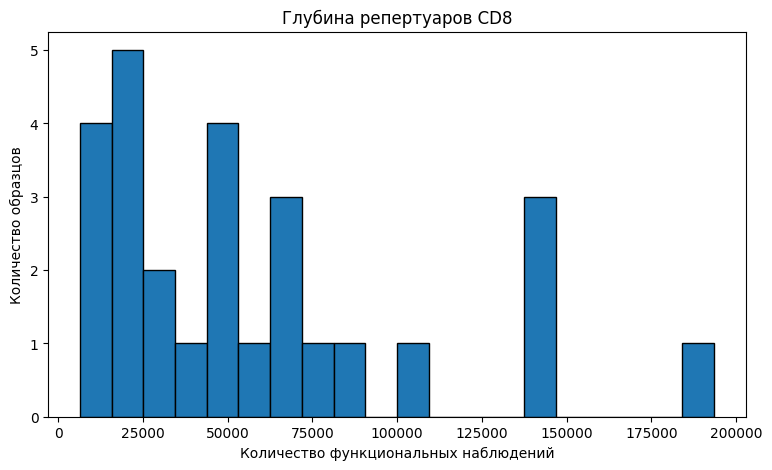

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(depths.dropna(), bins=20, edgecolor="black")
plt.xlabel("Количество функциональных наблюдений")
plt.ylabel("Количество образцов")
plt.title("Глубина репертуаров CD8")
plt.show()

In [ ]:
for depth in [1000, 2000, 3000, 4500, 5000, 6000, 10000]:
    n = (depths >= depth).sum()
    print(f"Глубина {depth}: {n} из {len(depths)} образцов")

Глубина 1000: 27 из 27 образцов
Глубина 2000: 27 из 27 образцов
Глубина 3000: 27 из 27 образцов
Глубина 4500: 27 из 27 образцов
Глубина 5000: 27 из 27 образцов
Глубина 6000: 27 из 27 образцов
Глубина 10000: 24 из 27 образцов


Для анализа TCRβ-репертуаров nCD8 выбрем глубину даунсэмплирования = 6000 наблюдений (минимальная глубина среди 27 образцов составила 6368, медианная — 50 019, максимальная — 193 529 наблюдений)

In [ ]:
# Заранее определяем фильтр продуктивных клонов и фильтр с равной глубиной 4500.
# # Внимание: отдельная колонка UMI в этих клоносетах отсутствует; см. примечание выше. (для CD4 взяла 5000 глубину)
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=6000, by_umi=True, seed=100)

## Filters

In [ ]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

### Functional

In [ ]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

### Top

In [ ]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

### Downsample

In [ ]:
# Случайно приводим образцы к глубине 4500 наблюдений с фиксированным seed.
downsample_filter = clf.Filter(functionality="f", downsample=6000, by_umi=True, seed=100)
downsample_filter

# Analysis

## CDR3 properties

In [ ]:
from pathlib import Path
import repseq
import repseq.stats as repseq_stats

# Ищем таблицу свойств аминокислот
repseq_dir = Path(repseq.__file__).resolve().parent

files = list(repseq_dir.rglob("aa_property_table.txt"))

print("Найденные файлы:", files)
print("Старый путь:", repseq_stats.AA_PROPS_PATH)

Найденные файлы: [PosixPath('/usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt')]
Старый путь: /root/soft/repseq/repseq/resourses/aa_property_table.txt


In [ ]:
if files:
    repseq_stats.AA_PROPS_PATH = str(files[0])
    print("Новый путь:", repseq_stats.AA_PROPS_PATH)
else:
    print("Файл не найден в установленной библиотеке repseq")

Новый путь: /usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt


In [ ]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd8, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,UCB3_nCD8_TRB_1,TRB,42.408038,5.268664,0.105407,0.000020,-3.368923,-3.668831,-0.068556,-0.684939,...,5.858554,14.711788,4.492580,13.986644,4.835745,13.841674,0.290640,0.763013,2.165004,2.479246
1,UCB11_nCD8_TRB_1,TRB,41.646803,4.922318,0.124502,0.000015,-3.738070,-3.389667,-0.065525,-0.601614,...,5.842366,14.385217,4.496546,13.759784,4.844603,13.605220,0.290846,0.747017,2.188666,2.382568
2,c4_nCD8_TRB_1,TRB,43.241642,7.000698,0.025467,0.000027,-3.636442,-4.126164,-0.097234,-0.746749,...,5.907985,15.041872,4.485906,14.275806,4.801015,14.065160,0.288009,0.775499,2.356183,2.879315
3,UCB13_nCD8_TRB_1,TRB,42.122559,5.696076,0.086504,0.000024,-3.668463,-3.464806,-0.070706,-0.653986,...,5.867639,14.560540,4.505142,13.948072,4.812484,13.717956,0.290146,0.754900,2.276620,2.594243
4,UCB12_nCD8_TRB_1,TRB,42.765448,5.990474,0.068314,0.000051,-3.445503,-3.327922,0.026090,-0.513217,...,5.823235,14.805898,4.493573,14.077000,4.840383,13.972930,0.289971,0.769046,2.115560,2.385814
5,o1_nCD8_TRB_1,TRB,43.324907,7.304388,0.025048,0.000029,-3.648183,-4.068196,-0.025575,-0.622575,...,5.849771,15.015972,4.495659,14.281683,4.825410,14.134755,0.288660,0.776980,2.257726,2.664560
6,UCB4_nCD8_TRB_1,TRB,42.294834,5.994483,0.061248,0.000066,-3.550628,-3.677452,-0.085021,-0.707684,...,5.884632,14.665745,4.494832,13.960893,4.812020,13.791584,0.289566,0.759499,2.267506,2.531124
7,UCB10_nCD8_TRB_1,TRB,42.186734,5.681539,0.080112,0.000012,-3.818655,-3.599789,-0.093696,-0.654887,...,5.867526,14.608763,4.507009,13.939814,4.810596,13.749601,0.289817,0.756286,2.296035,2.556039
8,c1_nCD8_TRB_1,TRB,43.008672,7.370145,0.022018,0.000022,-3.909778,-3.416638,0.051341,-0.450538,...,5.842508,14.870714,4.489455,14.161060,4.822227,14.046562,0.288655,0.770913,2.335863,2.621648
9,a6_nCD8_TRB_1,TRB,43.272277,7.352341,0.023528,0.000052,-3.341597,-3.769263,-0.134413,-0.749891,...,5.860428,15.005218,4.507167,14.310524,4.823279,14.090764,0.287840,0.775569,2.223227,2.656118


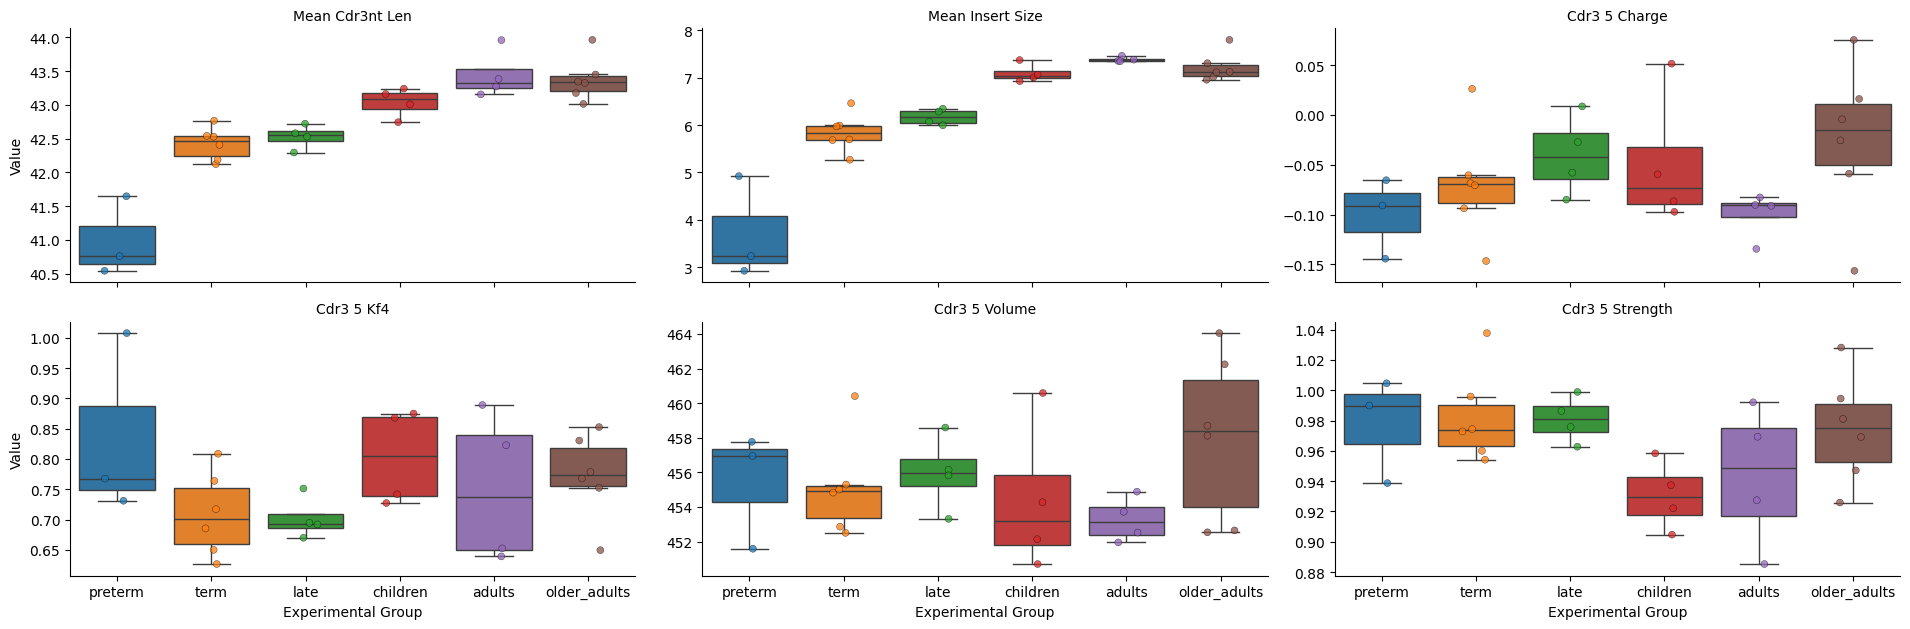

In [ ]:
# Отображаем свойства CDR3 по экспериментальным группам, один образец — одно наблюдение.
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [ ]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

## CDR3len distributions

In [ ]:
# Выбираем только nTreg из групп preterm и late для иллюстрации сравнения сроков.
preterm_late_cd8 = clonosets_cd8.query("experimental_group in ['preterm', 'late']")
preterm_late_cd8

,sample_id,chain,filename,experimental_group,donor_id,subset,source
1,UCB11_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB11,nCD8,UCB
6,UCB4_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB4,nCD8,UCB
12,UCB7_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB7,nCD8,UCB
13,UCB9_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB9,nCD8,UCB
18,UCB8_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,late,UCB8,nCD8,UCB
21,UCB1_nCD8_TRB_2,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB1,nCD8,UCB
25,UCB5_nCD8_TRB_1,TRB,/content/drive/MyDrive/Colab Notebooks/ImmuneS...,preterm,UCB5,nCD8,UCB


In [ ]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_cd8,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD8_TRB_1,TRB,4,0.000014
1,UCB11_nCD8_TRB_1,TRB,5,0.000041
2,UCB11_nCD8_TRB_1,TRB,6,0.000035
3,UCB11_nCD8_TRB_1,TRB,7,0.000104
4,UCB11_nCD8_TRB_1,TRB,8,0.000801
...,...,...,...,...
163,UCB9_nCD8_TRB_1,TRB,23,0.000041
164,UCB9_nCD8_TRB_1,TRB,24,0.000016
165,UCB9_nCD8_TRB_1,TRB,26,0.000005
166,UCB9_nCD8_TRB_1,TRB,27,0.000005


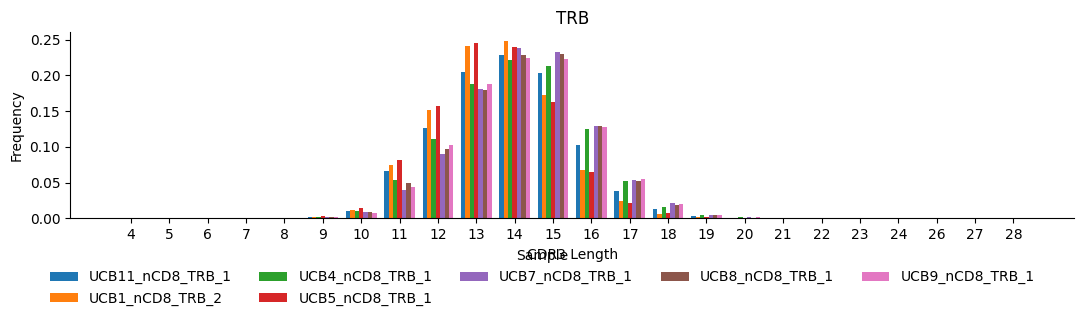

In [ ]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

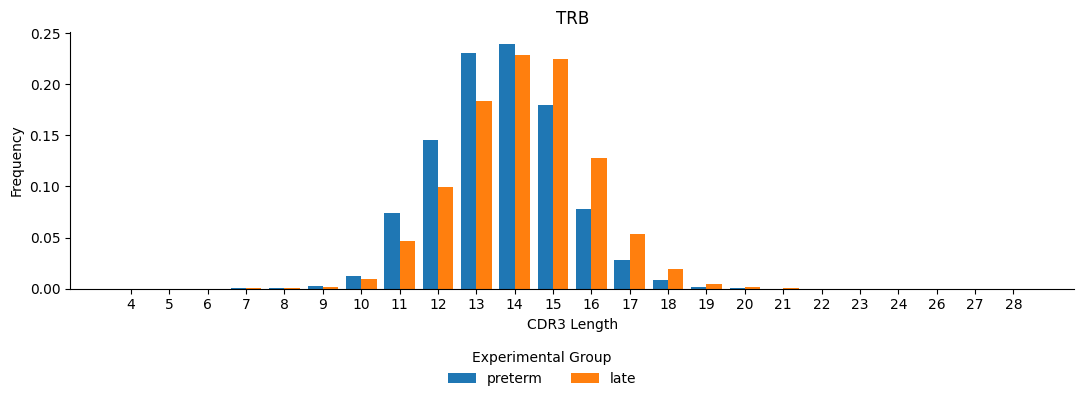

In [ ]:
# Показываем те же распределения, добавляя возрастные/экспериментальные группы.
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

## Segment usage

### V-usage

In [ ]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets_cd8, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,v,usage
0,UCB3_nCD8_TRB_1,TRB,TRBV1,0.000562
1,UCB11_nCD8_TRB_1,TRB,TRBV1,0.000332
2,c4_nCD8_TRB_1,TRB,TRBV1,0.000155
3,UCB13_nCD8_TRB_1,TRB,TRBV1,0.000169
4,UCB12_nCD8_TRB_1,TRB,TRBV1,0.000257
...,...,...,...,...
1669,c2_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1670,c5_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1671,o4_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1672,UCB5_nCD8_TRB_1,TRB,TRBV22-1,0.000029


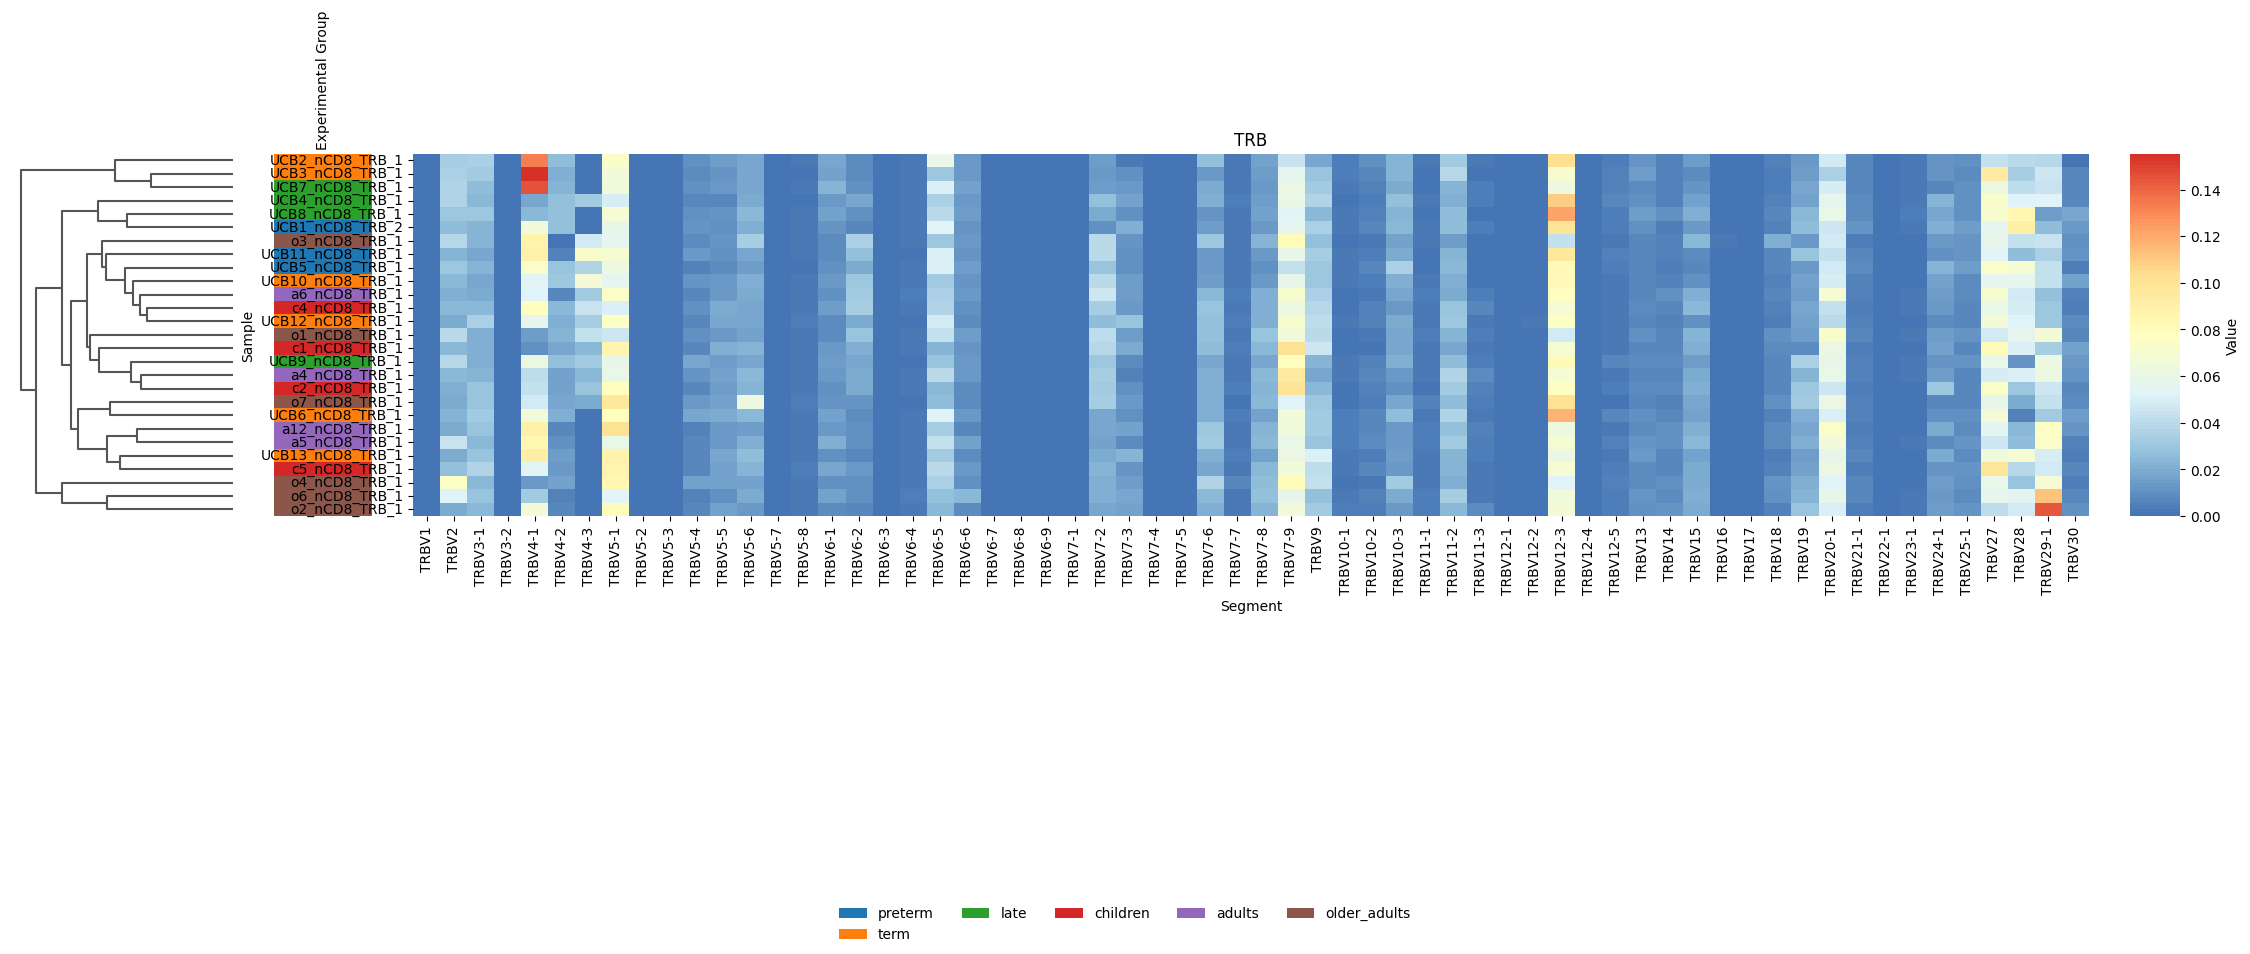

In [ ]:
# Тепловая карта: образцы или группы сопоставляются по профилям использования V.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

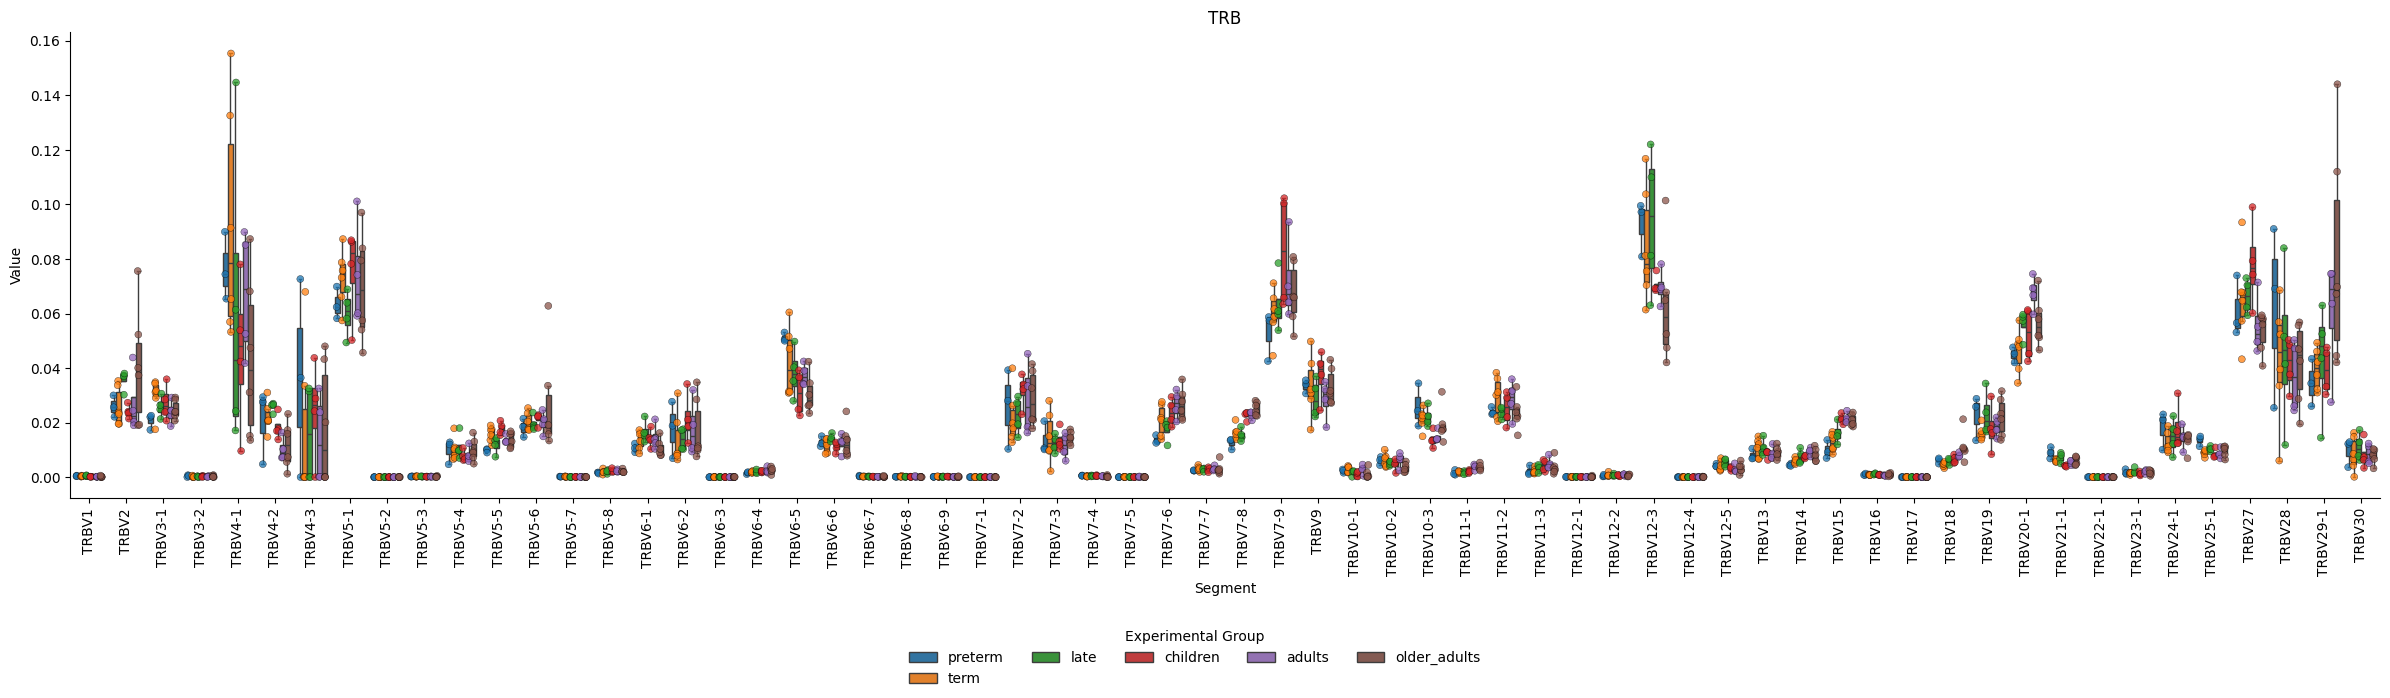

In [ ]:
# Boxplot показывает вариацию использования V-сегментов между образцами групп.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

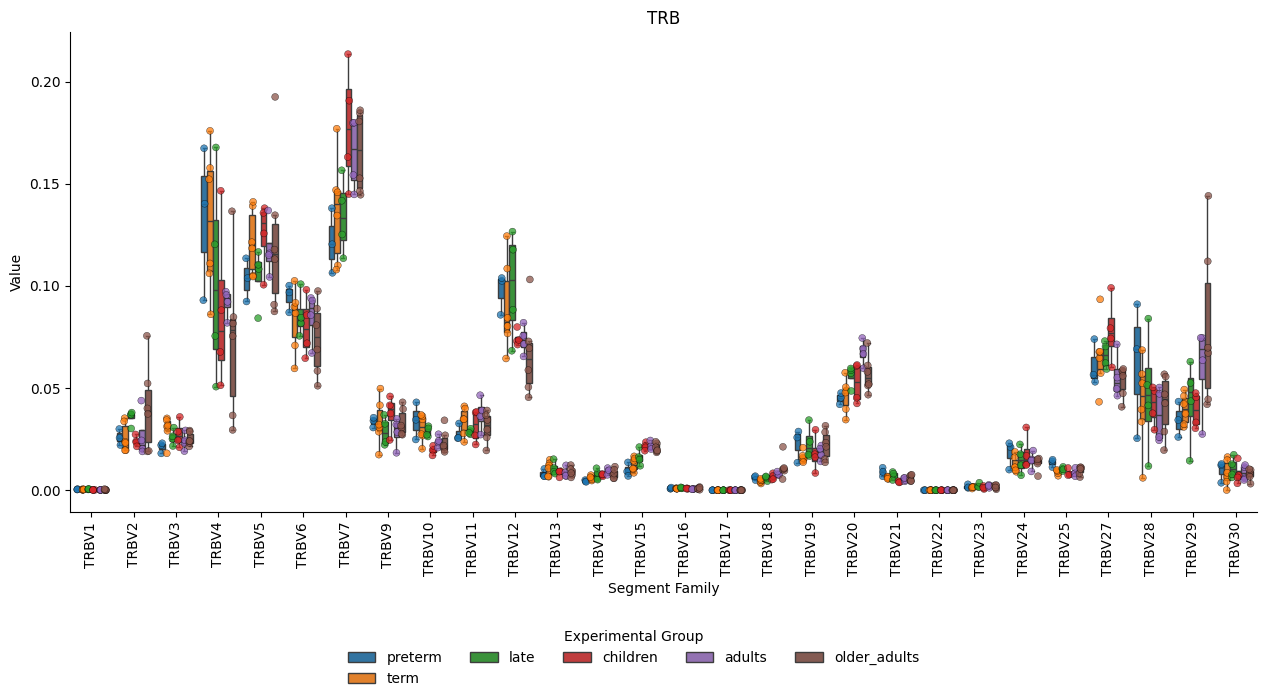

In [ ]:
# Объединяем V-гены по семействам, чтобы увидеть более крупные закономерности.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

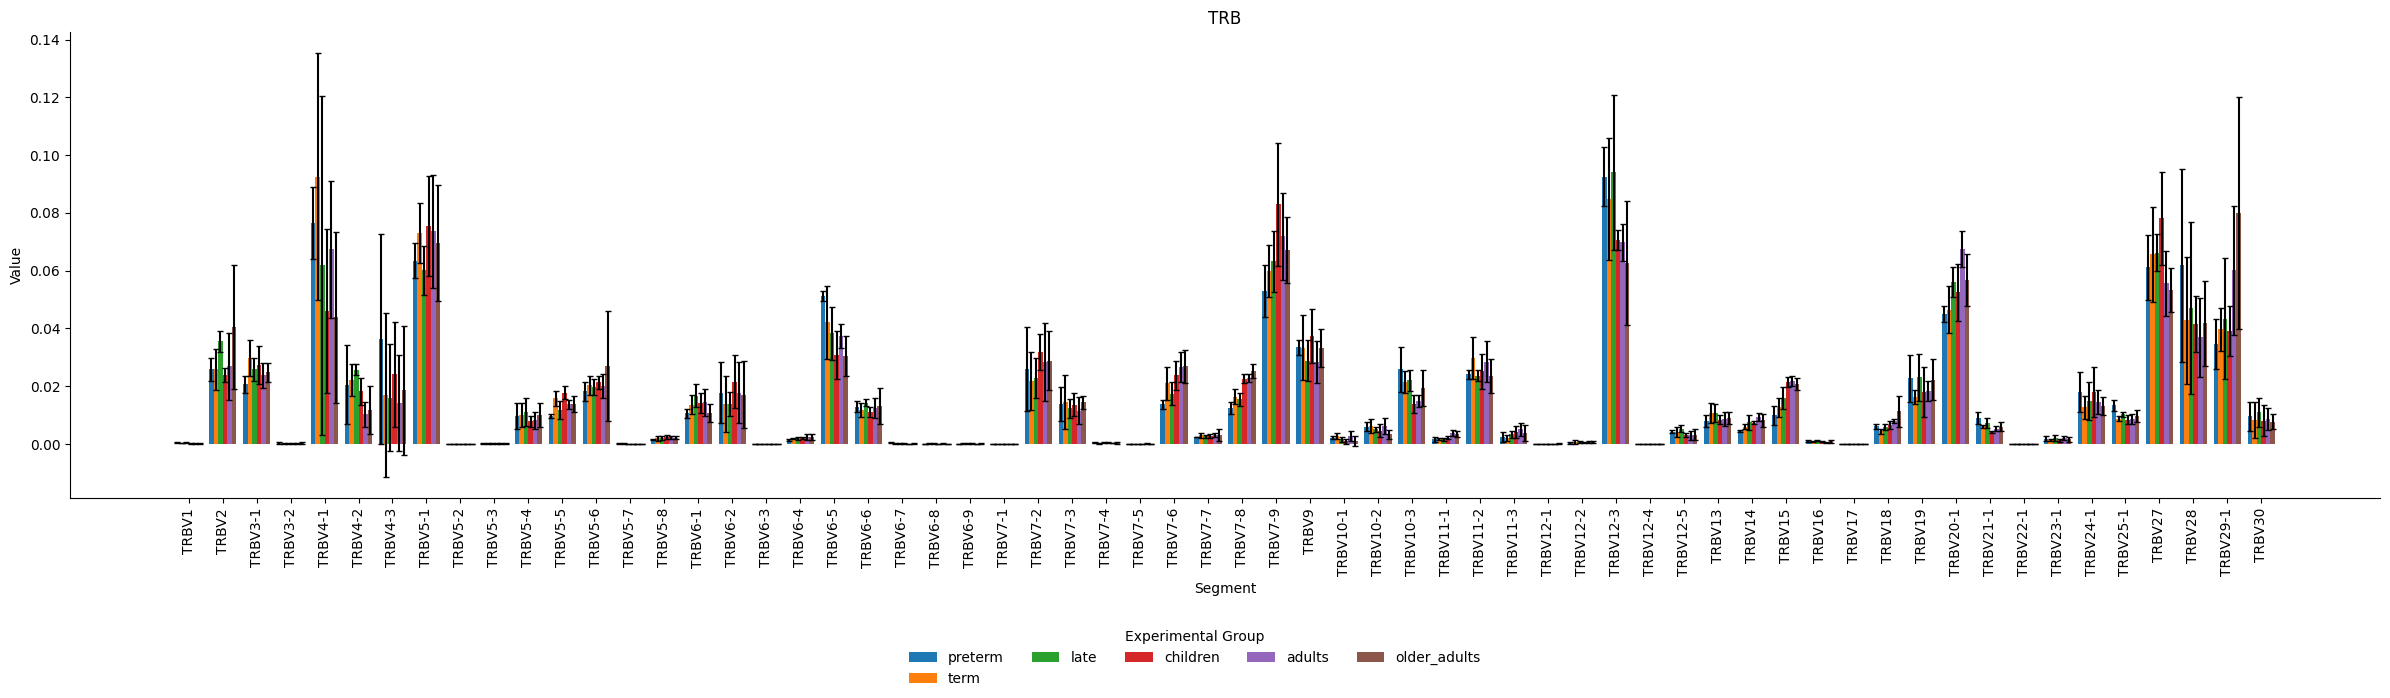

In [ ]:
# Barplot показывает частоты отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

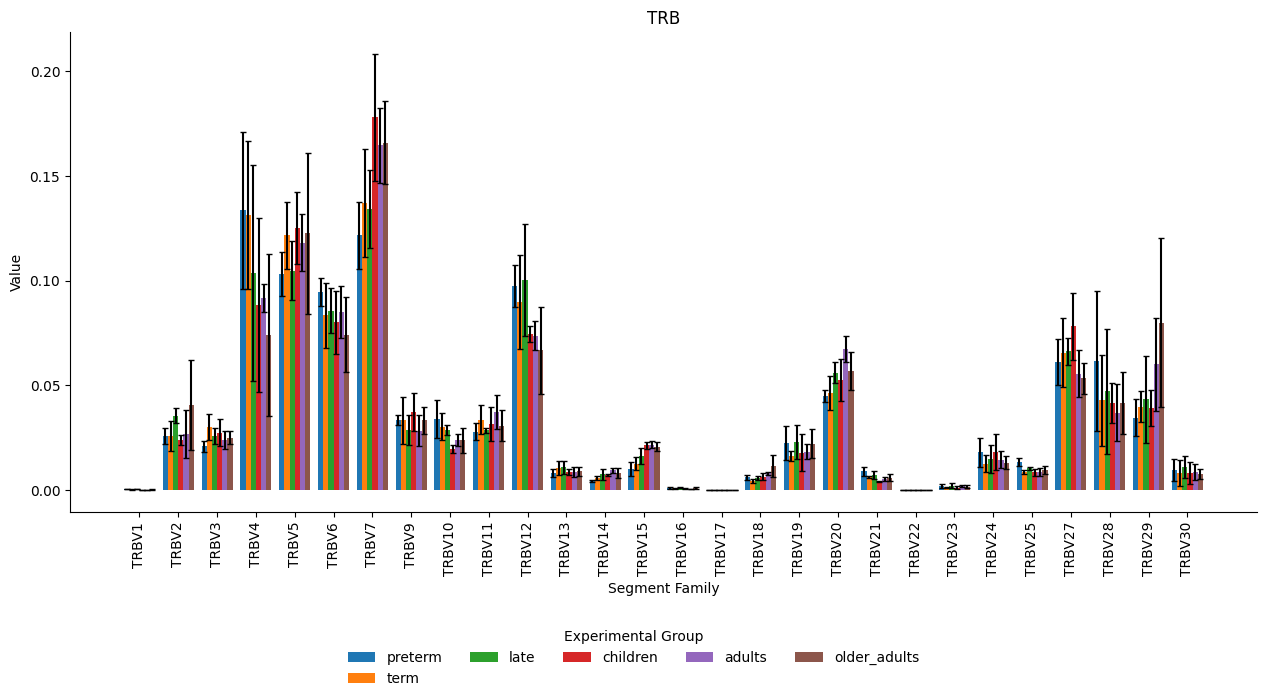

In [ ]:
# Barplot для частот V-семейств вместо отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [ ]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets_cd8, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,j,usage
0,UCB3_nCD8_TRB_1,TRB,TRBJ1-1,0.081952
1,UCB11_nCD8_TRB_1,TRB,TRBJ1-1,0.103157
2,c4_nCD8_TRB_1,TRB,TRBJ1-1,0.065372
3,UCB13_nCD8_TRB_1,TRB,TRBJ1-1,0.076421
4,UCB12_nCD8_TRB_1,TRB,TRBJ1-1,0.101485
...,...,...,...,...
346,c2_nCD8_TRB_1,TRB,TRBJ2-7,0.148130
347,c5_nCD8_TRB_1,TRB,TRBJ2-7,0.181137
348,o4_nCD8_TRB_1,TRB,TRBJ2-7,0.193440
349,UCB5_nCD8_TRB_1,TRB,TRBJ2-7,0.232826


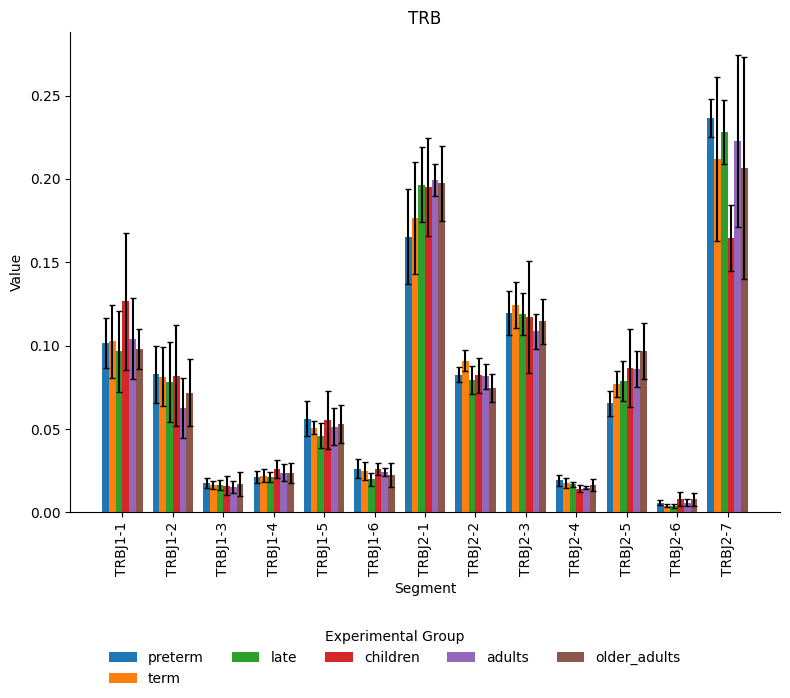

In [ ]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

**Конвергенция нуклеотидных последовательностей.** Разные CDR3 на уровне ДНК могут кодировать **одинаковую CDR3 на уровне белка** благодаря вырожденности генетического кода и независимым событиям перестройки. Простая мера — число различных CDR3nt, делённое на число различных CDR3aa. При добавлении требований совпадения V или V+J получаются более строгие варианты (`convergence_v`, `convergence_vj`).

Конвергенция зависит также от длины CDR3 и механизма генерации последовательностей; **её увеличение само по себе не доказывает антиген-индуцированную экспансию**. Для сравнения образцов применён одинаковый даунсэмпл.

## Convergence

In [ ]:
# Вычисляем конвергенцию после стандартизации глубины образцов.
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(clonosets_cd8,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence

CalcConvergence settings: seed=42, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,UCB3_nCD8_TRB_1,TRB,1.024923,1.006004,1.006004
1,UCB11_nCD8_TRB_1,TRB,1.032607,1.006209,1.006209
2,c4_nCD8_TRB_1,TRB,1.003738,1.001065,1.001065
3,UCB13_nCD8_TRB_1,TRB,1.013567,1.003710,1.003710
4,UCB12_nCD8_TRB_1,TRB,1.011835,1.002344,1.002344
5,o1_nCD8_TRB_1,TRB,1.003613,1.000901,1.000901
6,UCB4_nCD8_TRB_1,TRB,1.010524,1.001967,1.001967
7,UCB10_nCD8_TRB_1,TRB,1.015436,1.002246,1.002246
8,c1_nCD8_TRB_1,TRB,1.003336,1.000876,1.000876
9,a6_nCD8_TRB_1,TRB,1.007442,1.001032,1.001032


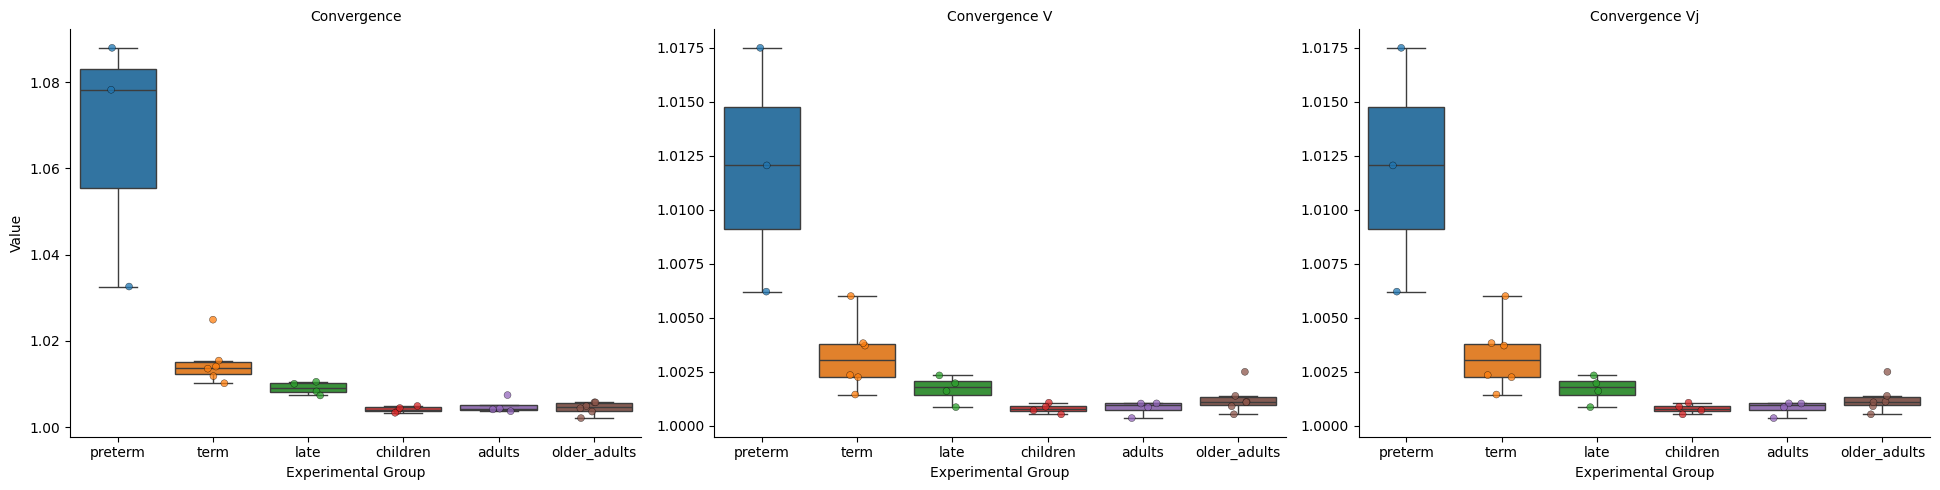

In [ ]:
# Показываем конвергенцию и её варианты по экспериментальным группам.
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

**Альфа-разнообразие — разнообразие *внутри* одного образца.** Несколько важных метрик:

- **`diversity`** — число обнаруженных клонотипов (богатство); чувствительно к глубине наблюдений.
- **`shannon_wiener`**: $H=-\sum_i p_i\ln p_i$; учитывает и богатство, и равномерность частот.
- **`norm_shannon_wiener`**: нормированная мера равномерности, обычно $H/\ln S$ (при $S>1$); ближе к 1, если частоты более равномерны.
- **`clonality`** — показатель противоположной направленности: больший вклад немногих клонов означает более выраженную клональность.
- Дополнительные метрики в таблице (`chao1`, `simpson`, `inverse_simpson`, `d50`, `gini_coefficient` и др.) по-разному чувствительны к редким и частым клонотипам.

`iterations=3` повторяет случайное субсэмплирование несколько раз; сравнивайте группы по распределению **образцов**, не воспринимая эти повторы как новые независимые биологические реплики. В данном примере настройка `seed` в самой функции и в фильтре могут различаться — ориентируйтесь на параметры расчёта в её логе.

## Diversity stats

In [ ]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets_cd8,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False,
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats settings: seed=123, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,UCB3_nCD8_TRB_1,TRB,5730.0,0.997964,0.002036,8.635854,67374.448560,5730.0,67550.303129,0.087667,0.476440,0.000183,5479.452055,0.999818,0.000667,0.043089
1,UCB11_nCD8_TRB_1,TRB,5702.0,0.997771,0.002229,8.629297,60274.754647,5702.0,60417.024813,0.096833,0.473869,0.000184,5431.502716,0.999816,0.000667,0.047320
2,c4_nCD8_TRB_1,TRB,5695.0,0.997566,0.002434,8.626294,60761.082707,5695.0,64623.932652,0.097833,0.473222,0.000186,5381.165919,0.999814,0.001333,0.048498
3,UCB13_nCD8_TRB_1,TRB,5786.0,0.998354,0.001646,8.648937,88729.191489,5786.0,88104.858769,0.069167,0.481507,0.000179,5577.936164,0.999821,0.000500,0.034498
4,UCB12_nCD8_TRB_1,TRB,5679.0,0.997563,0.002437,8.623460,57336.610714,5679.0,57246.944924,0.103500,0.471738,0.000186,5384.385283,0.999814,0.000667,0.050847
5,o1_nCD8_TRB_1,TRB,5634.0,0.996386,0.003614,8.605359,59489.219697,5634.0,64669.398430,0.111167,0.467519,0.000197,5080.440305,0.999803,0.002500,0.058275
6,UCB4_nCD8_TRB_1,TRB,5161.0,0.993864,0.006136,8.496427,19996.214286,5161.0,20154.782119,0.263500,0.418717,0.000219,4556.962025,0.999781,0.000833,0.121821
7,UCB10_nCD8_TRB_1,TRB,5818.0,0.998599,0.001401,8.656566,98911.000000,5818.0,103422.264820,0.059500,0.484359,0.000178,5633.802817,0.999822,0.001000,0.029455
8,c1_nCD8_TRB_1,TRB,5763.0,0.998230,0.001770,8.643884,76366.133641,5763.0,76151.695293,0.077333,0.479438,0.000180,5543.578688,0.999820,0.000500,0.038007
9,a6_nCD8_TRB_1,TRB,5862.0,0.998892,0.001108,8.666633,139445.560976,5862.0,145290.540175,0.044500,0.488229,0.000175,5712.472231,0.999825,0.000833,0.022526


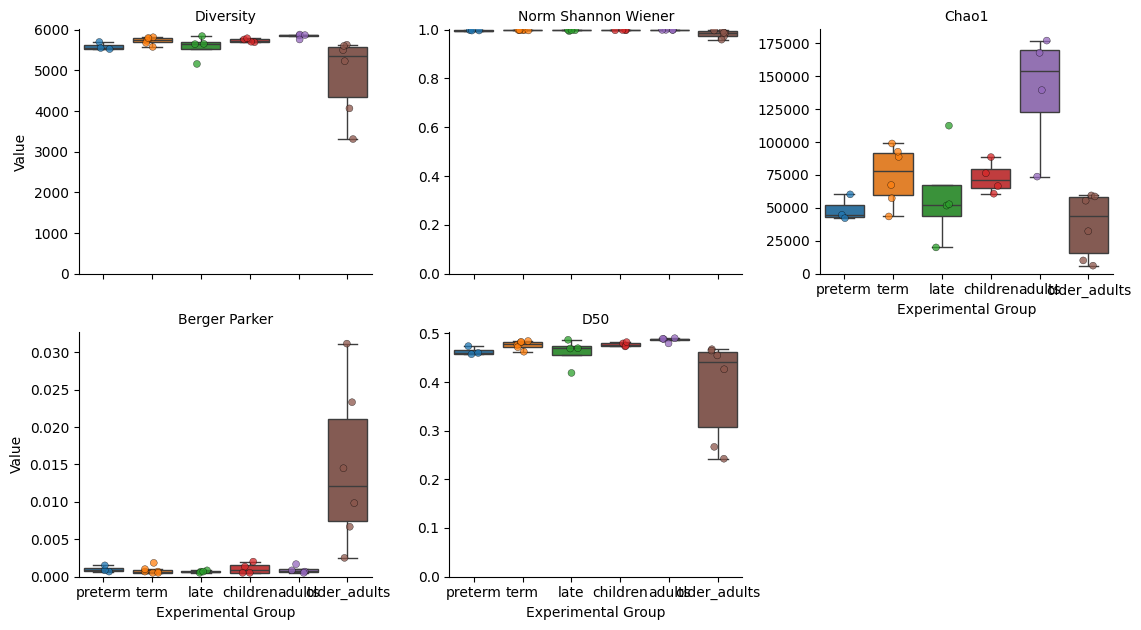

In [ ]:
# Визуализируем богатство, равномерность, клональность и другие индексы.
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )

CalcDiversityStats settings: seed=123, downsample=4500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


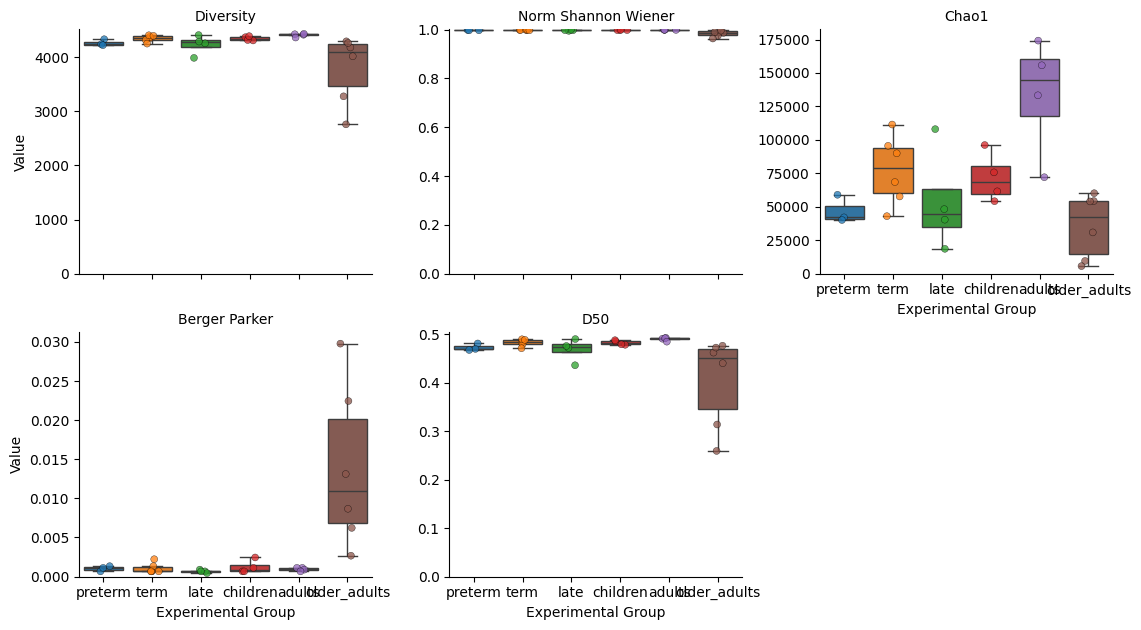

In [ ]:
# Альтернативный фильтр с глубиной 4500
filter_4500 = clf.Filter(
    functionality="f",
    downsample=4500,
    by_umi=True,
    seed=100)

diversity_4500 = stats.calc_diversity_stats(clonosets_cd8,
    cl_filter=filter_4500,
    seed=123,
    cpu=2,
    iterations=3,
    drop_small_samples=False,
    verbose=True
)
rsplot.diversity_stats(diversity_4500,
    metadata=metadata,
    group="experimental_group"
)

**Rarefaction (кривые разрежения).** Для каждого образца считаем, сколько различных клонотипов обнаружилось бы при разных глубинах выборки. По оси X — `rarefaction_depth` (число наблюдений), по оси Y — ожидаемое обнаруженное богатство `diversity`.

Если кривая выходит на плато, новые наблюдения добавляют мало новых клонотипов. Для TCR-репертуара всего организма плато часто недостижимо на небольшом образце крови. **Не путать** насыщение секвенирования конкретной библиотеки ридами с насыщением биологического репертуара организма. Два графика отличаются только логарифмической/линейной шкалой X.

## Rarefaction

In [ ]:
# Для каждого образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd8, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD8_TRB_1,TRB,32,32.000000
1,UCB10_nCD8_TRB_1,TRB,100,100.000000
2,UCB10_nCD8_TRB_1,TRB,316,315.666667
3,UCB10_nCD8_TRB_1,TRB,1000,994.666667
4,UCB10_nCD8_TRB_1,TRB,3162,3107.333333
...,...,...,...,...
202,o7_nCD8_TRB_1,TRB,100,99.000000
203,o7_nCD8_TRB_1,TRB,316,304.333333
204,o7_nCD8_TRB_1,TRB,1000,962.000000
205,o7_nCD8_TRB_1,TRB,3162,2977.666667


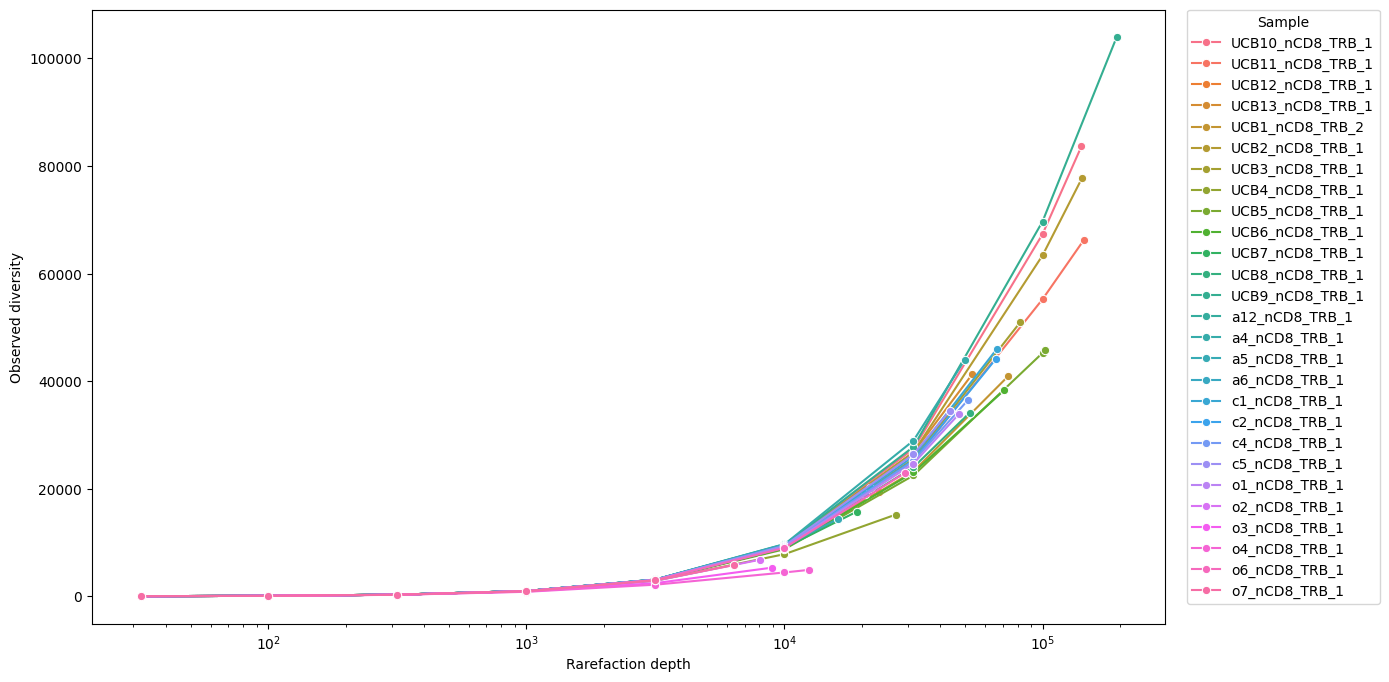

In [ ]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

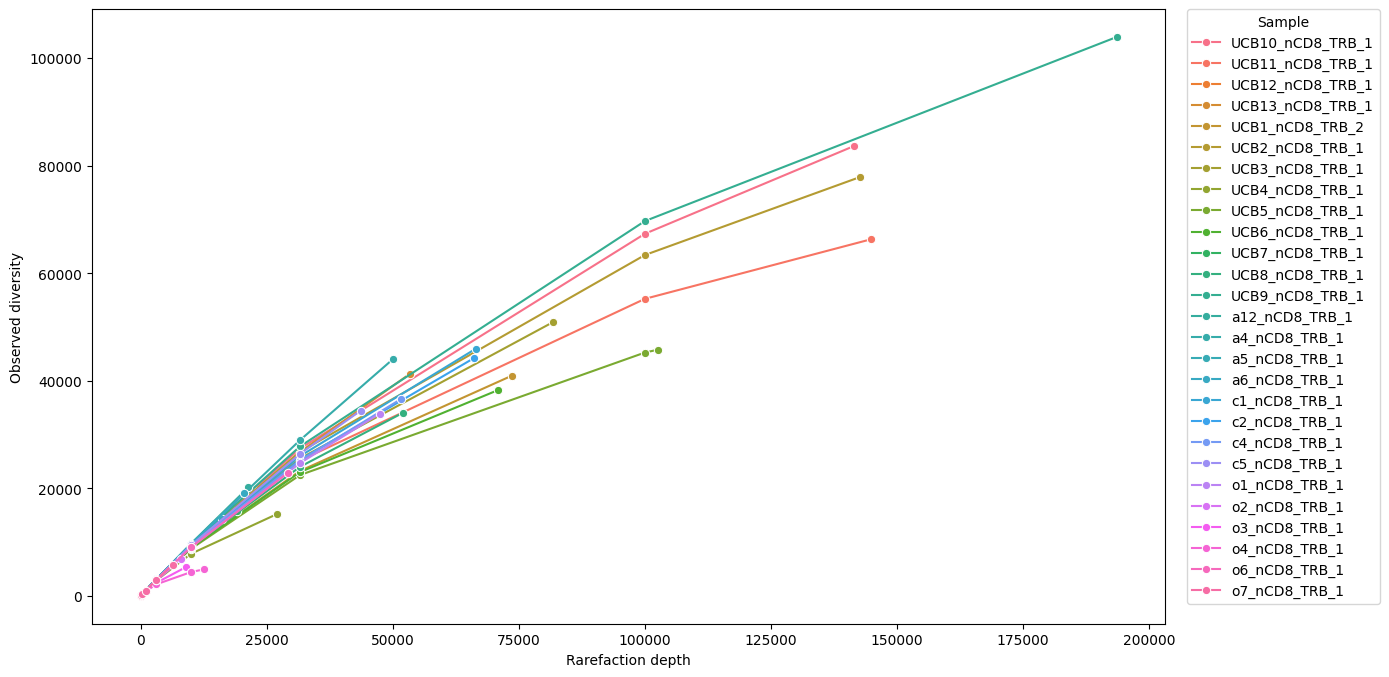

In [ ]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

**Бета-разнообразие — сходство *между* образцами.** Мы сравниваем не просто численность клонов, а пересечение определённых последовательностей. В этом ноутбуке совпадение задаётся `overlap_type='aaV'`: **одинаковая аминокислотная CDR3 и один V-ген**. Совпадение только CDR3aa без учёта V — менее строгое правило.

Для двух репертуаров $A$ и $B$ метрика **F2** выражается как $F_2(A,B)=\sum_{i\in A\cap B}\sqrt{p_iq_i}$, где $p_i$, $q_i$ — частоты совпавшего клонотипа в каждом образце. Чем больше F2, тем выше сходство по совпадающим последовательностям с учётом их частот. Диагональ матрицы при одинаковых правилах определения клонотипа равна 1; почти нулевые значения между людьми ожидаемы из-за индивидуального разнообразия TCR.

Это **описательная мера сходства**, а не p-value и не результат теста на различия между экспериментальными группами.

## Beta-diversity

### Main function for beta-diversity

In [ ]:
# Считаем попарное сходство клоносетов и таблицы пересечений.
# # aaV означает совпадение CDR3aa И V-гена; значение F2 — сходство, не расстояние.
beta_diversity = beta.metrics(clonosets_cd8,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=None                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 27/27 sample(s) processed
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Intersecting clonosets |##################################################| 351/351 pairs processed


In [ ]:
# Смотрим, какие метрики и таблицы вернула функция beta.metrics.
beta_diversity.keys()

dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [ ]:
# Отдельно открываем квадратную матрицу попарного сходства F2.
beta_diversity["f2"]

sample2,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB12_nCD8_TRB_1,UCB13_nCD8_TRB_1,UCB1_nCD8_TRB_2,UCB2_nCD8_TRB_1,UCB3_nCD8_TRB_1,UCB4_nCD8_TRB_1,UCB5_nCD8_TRB_1,UCB6_nCD8_TRB_1,...,c1_nCD8_TRB_1,c2_nCD8_TRB_1,c4_nCD8_TRB_1,c5_nCD8_TRB_1,o1_nCD8_TRB_1,o2_nCD8_TRB_1,o3_nCD8_TRB_1,o4_nCD8_TRB_1,o6_nCD8_TRB_1,o7_nCD8_TRB_1
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD8_TRB_1,1.000000,0.009492,0.003971,0.006018,0.013359,0.005317,0.008375,0.005874,0.021049,0.003593,...,0.002374,0.002077,0.002207,0.001971,0.002707,0.002662,0.000736,0.000500,0.000500,0.003305
UCB11_nCD8_TRB_1,0.009492,1.000000,0.008484,0.008432,0.025391,0.008946,0.011854,0.007340,0.033090,0.008009,...,0.003305,0.002805,0.001833,0.003898,0.002971,0.005152,0.001191,0.001260,0.002760,0.005272
UCB12_nCD8_TRB_1,0.003971,0.008484,1.000000,0.003443,0.014593,0.002213,0.005423,0.005072,0.015301,0.002231,...,0.000500,0.001236,0.001593,0.001874,0.001638,0.003344,0.001191,0.001024,0.000833,0.001736
UCB13_nCD8_TRB_1,0.006018,0.008432,0.003443,1.000000,0.012931,0.005382,0.008365,0.005001,0.014874,0.004012,...,0.002398,0.002313,0.001667,0.001736,0.001805,0.002276,0.001524,0.001276,0.002138,0.002000
UCB1_nCD8_TRB_2,0.013359,0.025391,0.014593,0.012931,1.000000,0.014452,0.022482,0.012571,0.056981,0.012644,...,0.003231,0.005673,0.003801,0.005703,0.003634,0.005946,0.002423,0.001599,0.004276,0.004673
UCB2_nCD8_TRB_1,0.005317,0.008946,0.002213,0.005382,0.014452,1.000000,0.007065,0.004322,0.012807,0.005518,...,0.002138,0.002971,0.001000,0.003276,0.000942,0.002305,0.000333,0.000844,0.002260,0.003443
UCB3_nCD8_TRB_1,0.008375,0.011854,0.005423,0.008365,0.022482,0.007065,1.000000,0.006380,0.023424,0.005719,...,0.002138,0.002075,0.003040,0.003943,0.001333,0.003301,0.001622,0.002246,0.001858,0.002638
UCB4_nCD8_TRB_1,0.005874,0.007340,0.005072,0.005001,0.012571,0.004322,0.006380,1.000000,0.013792,0.002260,...,0.001638,0.001552,0.001305,0.003822,0.001980,0.002046,0.001996,0.001305,0.002138,0.002638
UCB5_nCD8_TRB_1,0.021049,0.033090,0.015301,0.014874,0.056981,0.012807,0.023424,0.013792,1.000000,0.011077,...,0.002868,0.005311,0.003236,0.003605,0.004284,0.008749,0.001813,0.001766,0.002775,0.004687


In [ ]:
print(beta_diversity["full_table"]["pair"].unique())

['UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB12_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB13_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB1_nCD8_TRB_2'
 'UCB10_nCD8_TRB_1_vs_UCB2_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB3_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB4_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB5_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB6_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB7_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB8_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_UCB9_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_a12_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_a4_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_a5_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_a6_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_c1_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_c2_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_c4_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_c5_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_o1_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_o2_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_o3_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_o4_nCD8_TRB_1'
 'UCB10_nCD8_TRB_1_vs_o6_nCD8_TRB_1' 'UCB10_nCD8_TRB_1_vs_o7_nCD8_TRB_1'
 'UCB11_nCD8_TRB_

In [ ]:
# Разбираем пересечение двух конкретных репертуаров на уровне клонотипов.
beta_diversity["full_table"].query("pair == 'UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1'")

,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CASSIGQGSYNEQFF,TRBV19,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
1,CASSLAGAIYEQYF,TRBV5-1,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
2,CSVAPDGLAKNIQYF,TRBV29-1,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
3,CASSLDSRPYEQYF,TRBV12-3,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
4,CASSEALTANTEAFF,TRBV2,1,0,0.000167,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
...,...,...,...,...,...,...,...,...,...
11367,CASSLRDNSYEQYF,TRBV5-8,1,0,0.000167,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11368,CASRDRDSSYEQYF,TRBV13,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11369,CASSYDTYNEQFF,TRBV6-5,1,0,0.000167,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11370,CASSLAGTEAFF,TRBV5-4,0,1,0.000000,0.000167,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1


**Как читать тепловую карту F2.** Каждая ячейка — результат сравнения **пары образцов**, а не отдельного клонотипа. `ignore_diagonal=True` убирает тривиальные сравнения образца с самим собой; `hclust=True` упорядочивает образцы иерархической кластеризацией. На карте можно искать группы похожих образцов, но визуальный кластер сам по себе не гарантирует статистическую значимость.

### Single metric heatmap plot

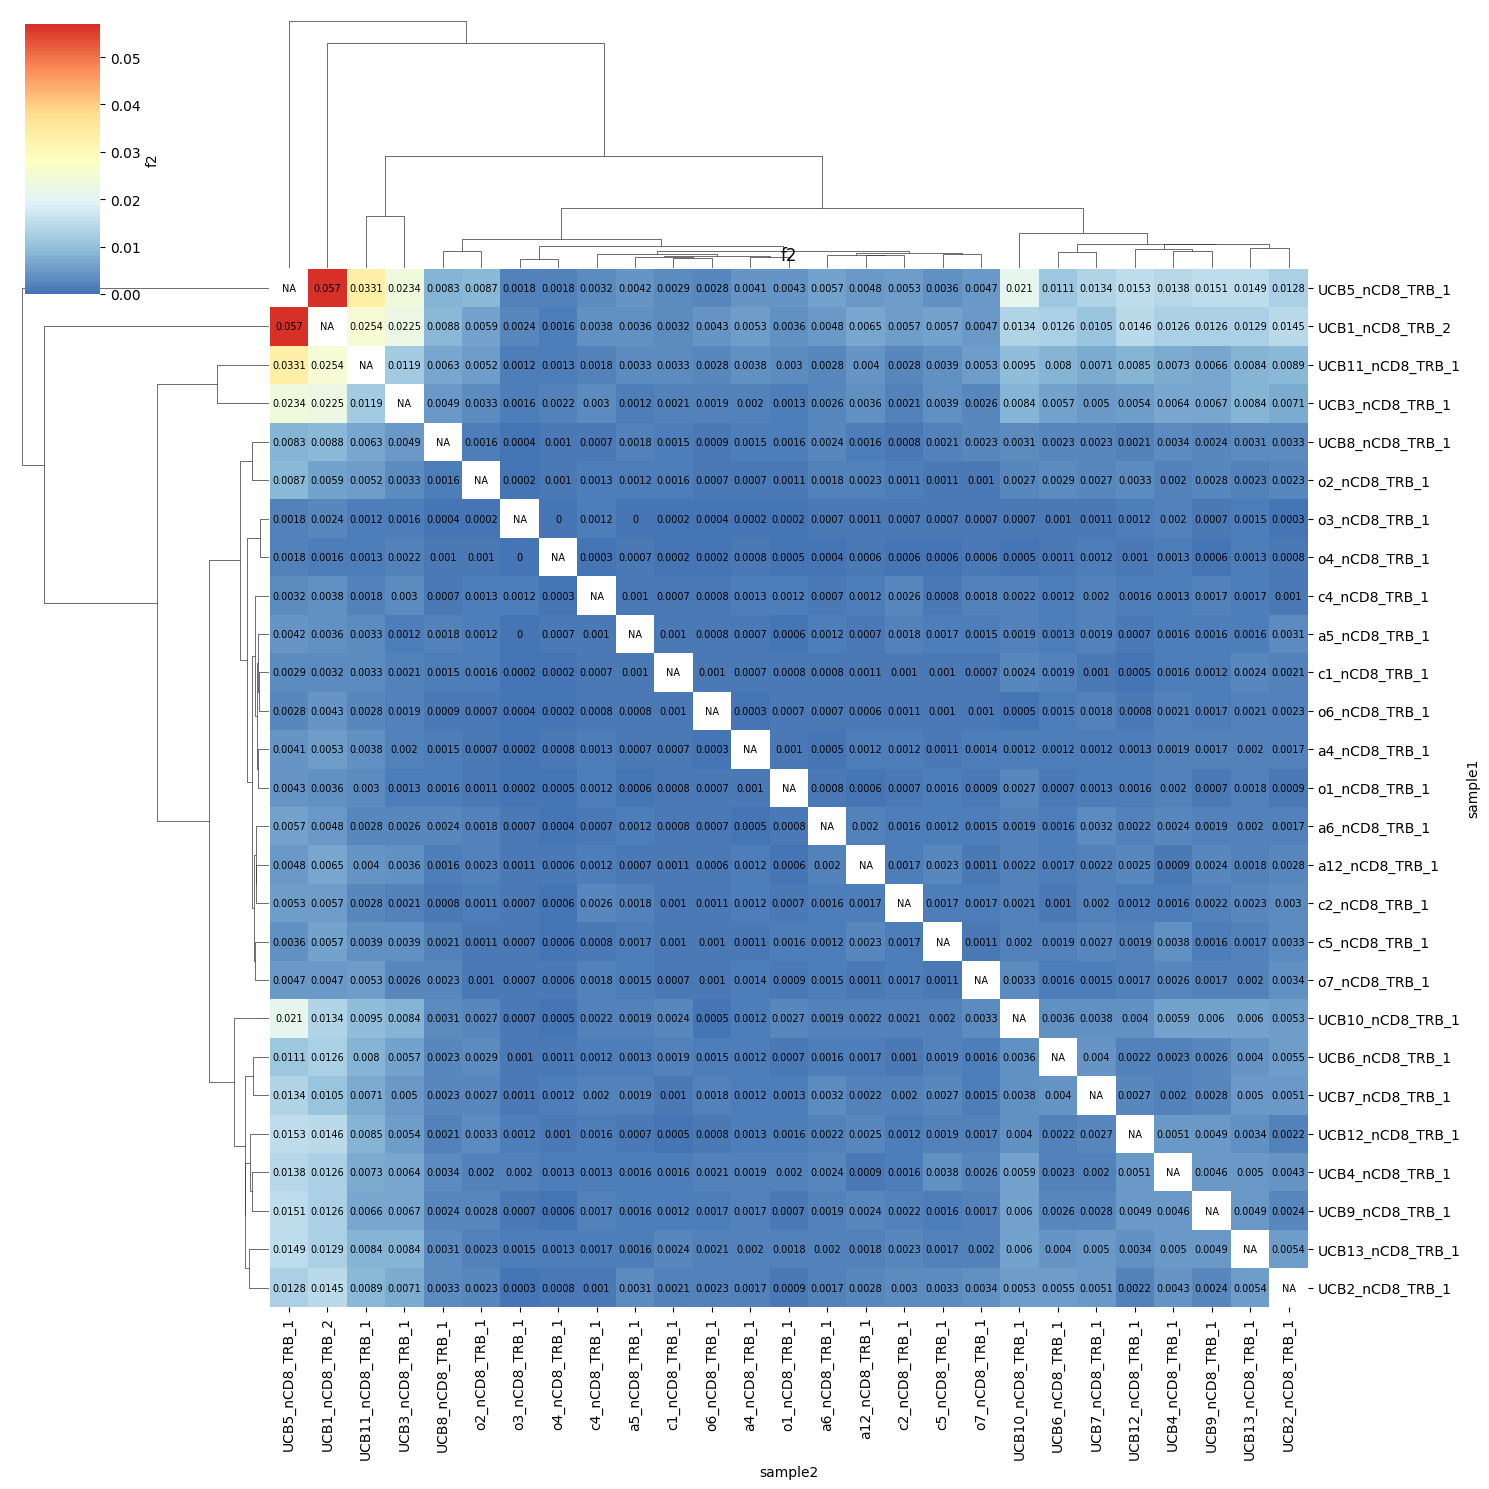

In [ ]:
# Показываем тепловую карту F2, скрываем диагональ, кластеризуем образцы по сходству.
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )

**MDS (multidimensional scaling).** Это способ разместить образцы в двумерном пространстве так, чтобы **более близким** в смысле исходной матрицы расстояний объектам соответствовали более близкие точки. Мера F2 — *сходство*, поэтому для методов расстояний её преобразуют (например, в материалах семинара обсуждается $d_{ij}=-\log_{10}(F2_{ij}+\varepsilon)$ с малым $\varepsilon$). Конкретные внутренние вычисления определяет реализация `beta.mds`.

`MDS1` и `MDS2` — **условные координаты**, а не биологические параметры. `centroids=True` показывает центры групп, `dispersion=True` — разброс. Оцениваем, насколько образцы одной группы сближаются; не делаем вывод о значимости без отдельного статистического анализа.

### MDS for metric

In [ ]:
# Преобразуем информацию о попарных отношениях между образцами в координаты MDS.
ucb_treg_mds = beta.mds(beta_diversity)
ucb_treg_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD8_TRB_1,-0.082130,0.058050
1,UCB11_nCD8_TRB_1,0.038118,-0.001066
2,UCB12_nCD8_TRB_1,-0.336715,0.942236
3,UCB13_nCD8_TRB_1,-0.142352,-0.021122
4,UCB1_nCD8_TRB_2,-0.150316,0.047974
5,UCB2_nCD8_TRB_1,0.366615,-0.515044
6,UCB3_nCD8_TRB_1,-0.157482,0.313307
7,UCB4_nCD8_TRB_1,-0.202106,0.158733
8,UCB5_nCD8_TRB_1,-0.035067,0.149344
9,UCB6_nCD8_TRB_1,-0.028849,-0.101977


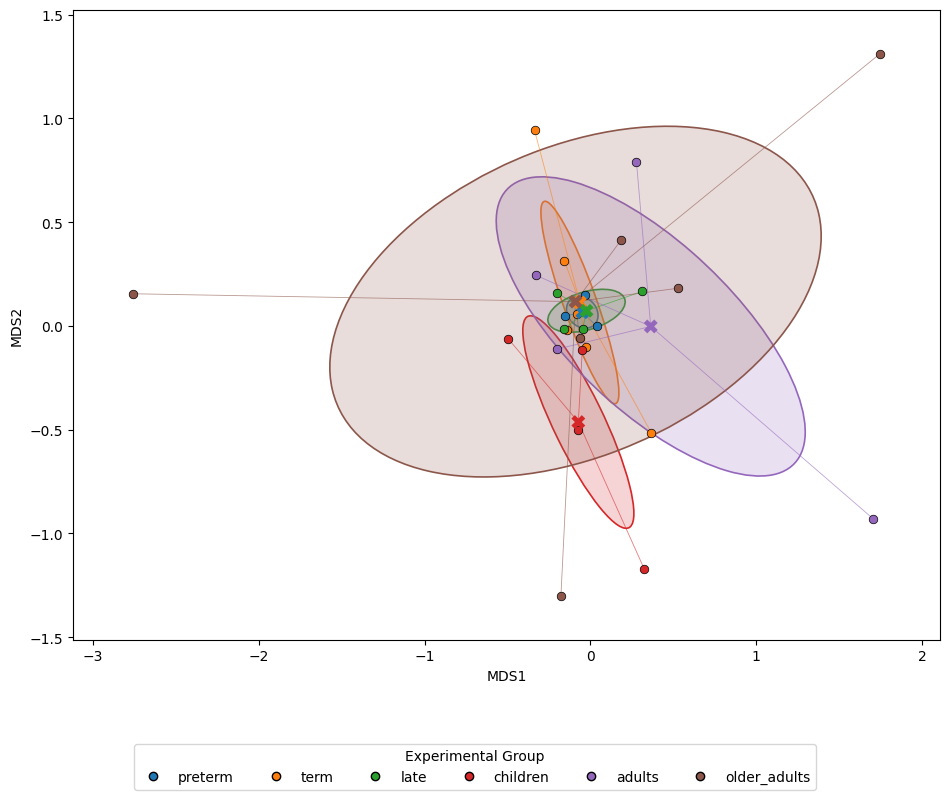

In [ ]:
# Рисуем две координаты MDS с цветом групп, центрами и разбросом.
rsplot.beta_mds(ucb_treg_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

**Кластеризация похожих CDR3.** Здесь **объекты — последовательности клонотипов**, а не образцы. Если две последовательности удовлетворяют правилу сходства, между ними можно провести ребро графа. `overlap_type='aaV'` использует аминокислотные CDR3 и V-ген, `mismatches=1` допускает одно несовпадение между сравниваемыми последовательностями.

Важная деталь: в связанном кластере две далёкие вершины могут отличаться **более чем на один символ**, поскольку соединяются цепочкой промежуточных вариантов. Такие кластеры — кандидаты для последующего поиска общей специфичности, но не прямое доказательство распознавания одного антигена. Расчёт и отрисовка могут быть тяжёлыми на больших данных.

## Clustering

### Create clusters

In [ ]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets_cd8, cl_filter=downsample_filter)

Pooled 149177 clonotypes from 27 samples


In [ ]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 149177 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 732/732 tasks processed
found 89243 edges
-----------------------------
NexworkX graph created
Found 7871 clusters (2 or more nodes) and 108269 single nodes. Total: 116140


In [ ]:
# Добавляем к вершинам/последовательностям метаданные экспериментальных групп.
clusters.add_metadata(metadata)

In [ ]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,83668,CASRRGTGELFF,TRBV12-3,TRBJ2-2,TGTGCCAGCAGGCGGGGCACCGGGGAGCTGTTTTTT,UCB13_nCD8_TRB_1,0.000167,1,None,2,term,UCB13,nCD8,UCB
1,0,96418,CASSLGTGELFF,TRBV12-3,TRBJ2-2,TGTGCCAGCAGTTTAGGCACCGGGGAGCTGTTTTTT,UCB11_nCD8_TRB_1,0.000167,1,None,30,preterm,UCB11,nCD8,UCB
2,0,97030,CASRKDTGELFF,TRBV12-3,TRBJ2-2,TGTGCCAGCAGAAAAGACACCGGGGAGCTGTTTTTT,UCB11_nCD8_TRB_1,0.000167,1,None,2,preterm,UCB11,nCD8,UCB
3,0,96725,CASSRGGETQYF,TRBV12-3,TRBJ2-5,TGTGCCAGCAGTAGGGGGGGCGAGACCCAGTACTTC,UCB3_nCD8_TRB_1,0.000167,1,None,7,term,UCB3,nCD8,UCB
4,0,42665,CASSDGTDTQYF,TRBV12-3,TRBJ2-3,TGTGCCAGCAGTGACGGCACAGATACGCAGTATTTT,c5_nCD8_TRB_1,0.000167,1,None,12,children,c5,nCD8,PB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149172,116135,126873,WREDTQYF,TRBV19,TRBJ2-3,TGGCGGGAAGATACGCAGTATTTT,o7_nCD8_TRB_1,0.000167,1,None,0,older_adults,o7,nCD8,PB
149173,116136,87829,WVAGLTGELFF,TRBV28,TRBJ2-2,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,o1_nCD8_TRB_1,0.000167,1,None,0,older_adults,o1,nCD8,PB
149174,116137,58525,YAIRDRGYEQYF,TRBV10-3,TRBJ2-7,TATGCCATCAGGGACAGGGGATACGAGCAGTACTTC,UCB5_nCD8_TRB_1,0.000167,1,None,0,preterm,UCB5,nCD8,UCB
149175,116138,143817,YSARGQENTGELFF,TRBV20-1,TRBJ2-2,TACAGTGCTCGGGGACAGGAGAACACCGGGGAGCTGTTTTTT,a6_nCD8_TRB_1,0.000167,1,None,0,adults,a6,nCD8,PB


In [ ]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |##################################################| 116140/116140 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,792,4005,882,23,0.012786,16.584596,CASSLGGYEQYF,TGTGCCAGCAGTTTAGGGGGCGATGAGCAGTACTTC,TRBV12-3,TRBJ2-7
1,1,cluster_1,712,4757,784,22,0.018794,14.948034,CASSLGGYEQFF,TGTGCCAGCAGCTTAGGGGGCAATGAGCAGTTCTTC,TRBV7-9,TRBJ2-7
2,2,cluster_2,567,2915,612,18,0.018166,13.014109,CASSLGGSYEQYF,TGTGCCAGCAGTTTAGGGGGGTCCTACGAGCAGTACTTC,TRBV27,TRBJ2-7
3,3,cluster_3,497,3343,553,14,0.027122,11.229376,CASSLGGYEQFF,TGCGCCAGCAGCTTGGGCGGCGATGAGCAGTTCTTC,TRBV5-1,TRBJ2-7
4,4,cluster_4,491,2680,561,16,0.022279,11.423625,CASSLGGGYEQYF,TGCGCCAGCAGCTTGGGAGGGGCCTACGAGCAGTACTTC,TRBV5-1,TRBJ2-7
...,...,...,...,...,...,...,...,...,...,...,...,...
116135,116135,cluster_116135,1,0,1,0,0.000000,0.000000,WREDTQYF,TGGCGGGAAGATACGCAGTATTTT,TRBV19,TRBJ2-3
116136,116136,cluster_116136,1,0,1,0,0.000000,0.000000,WVAGLTGELFF,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,TRBV28,TRBJ2-2
116137,116137,cluster_116137,1,0,1,0,0.000000,0.000000,YAIRDRGYEQYF,TATGCCATCAGGGACAGGGGATACGAGCAGTACTTC,TRBV10-3,TRBJ2-7
116138,116138,cluster_116138,1,0,1,0,0.000000,0.000000,YSARGQENTGELFF,TACAGTGCTCGGGGACAGGAGAACACCGGGGAGCTGTTTTTT,TRBV20-1,TRBJ2-2


In [ ]:
# Отбираем кластеры, исключая указанные V- и J-сегменты из демонстрации.
# # Поля concensus_v/concensus_j названы так в выводе библиотеки.
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
10,10,cluster_10,303,1324,327,20,0.028938,15.660066,CASSQGGDEQFF,TGCGCCAGCAGCCAAGAGGGCGATGAGCAGTTCTTC,TRBV4-1,TRBJ2-1
13,13,cluster_13,249,1062,272,16,0.034396,11.538153,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV27,TRBJ1-1
22,22,cluster_22,157,479,163,14,0.039115,10.254777,CASSLGGGYNEQFF,TGTGCCAGCAGTTTAGGGGGGGCCTACAATGAGCAGTTCTTC,TRBV27,TRBJ2-1
23,23,cluster_23,154,568,165,17,0.048213,13.032468,CASSYSGNTEAFF,TGTGCCAGCAGTTACTCGGGGAACACTGAAGCTTTCTTT,TRBV6-5,TRBJ1-1
24,24,cluster_24,144,611,161,10,0.059343,7.090278,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV12-3,TRBJ1-1
...,...,...,...,...,...,...,...,...,...,...,...,...
116132,116132,cluster_116132,1,0,1,0,0.000000,0.000000,WDNTGELFF,TGGGACAACACCGGGGAGCTGTTTTTT,TRBV9,TRBJ2-2
116133,116133,cluster_116133,1,0,1,0,0.000000,0.000000,WGGRNTEAFF,TGGGGAGGCAGAAACACTGAAGCTTTCTTT,TRBV9,TRBJ1-1
116134,116134,cluster_116134,1,0,1,0,0.000000,0.000000,WPEKAGVISTEAFF,TGGCCGGAAAAGGCTGGGGTTATTTCCACTGAAGCTTTCTTT,TRBV7-8,TRBJ1-1
116136,116136,cluster_116136,1,0,1,0,0.000000,0.000000,WVAGLTGELFF,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,TRBV28,TRBJ2-2


In [ ]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 149177
    samples: 27
    input_samples: 27
    filter:
      name: default_filter
      functionality: f
      downsample_size: 6000
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 149177 nodes and 89243 edges
Clusters: 7871 clusters (2 or more nodes) and 108269 single nodes. Total: 116140
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: experimental_group, donor_id, subset, source
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
print(downsample_filter)

Filter name:	default_filter
Functionality:	only functional clones (no frameshifts and Stops)
Downsample size:	6000
Count by:	 UMI (if exist)
Seed for random:	100



**Визуализация графа.** Вершины представляют последовательности/клонотипы, ребра — заданное выше сходство. Цвет показывает экспериментальную группу; подписи и размеры связаны с числом наблюдений. Здесь выводятся кластеры с номерами от 20 до 29; сами номера — **идентификаторы по результату текущего расчёта**, а не универсальные биологические метки. При другом входном наборе или параметрах их состав может измениться.

### Plot clusters

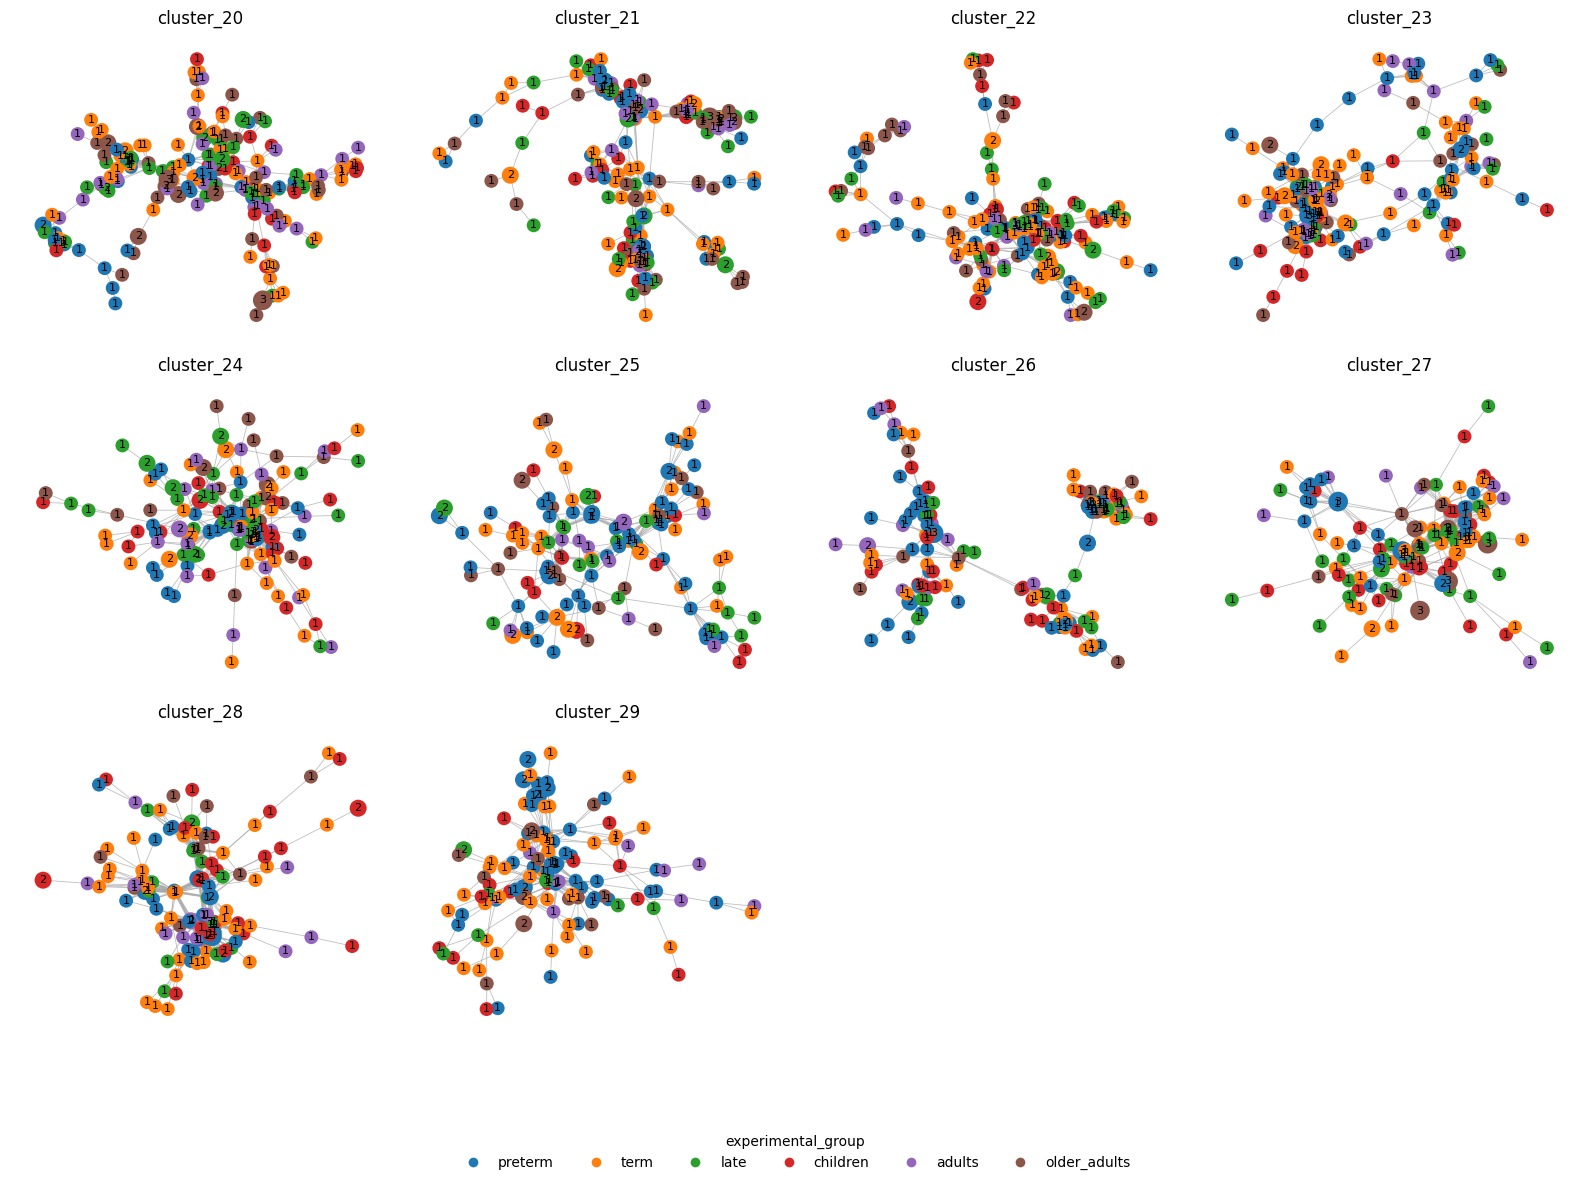

In [ ]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)

## Биологические выводы для nCD8

**1. Данные**

Проанализированы 27 образцов наивных CD8⁺ T-клеток (по одному на донора): preterm (n = 3), term (6), late (4), children (4), adults (4), older_adults (6). Глубина до выравнивания различалась (медиана 50 019, диапазон 6 368–193 529) и была связана с группой (≈ 103 тыс. у preterm, ≈ 11 тыс. у older_adults). Метрики считались после даунсэмплирования до 6000 наблюдений на образец (эта глубина сохраняет все 27 образцов)

**2. CDR3 и конвергенция**

 С возрастом растут длина CDR3nt и размер вставки, а доля клонотипов без вставок падает. Конвергенция снижается с 1,078 у preterm до 1,004 у adults. Все три preterm-образца выше всех остальных как и у nCD4

**3. Разнообразие, сходство, кластеры**

 При глубине 6000 у большинства образцов индексы разнообразия на потолке (число клонотипов 5161–5884 из 6000), поэтому они малоинформативны. Выделяется older_adults: у 4 из 6 образцов клональность 0,013–0,041, а во всех остальных группах не выше 0,0061. Это может быть реальной клональной экспансией или следствием малого входа материала, и данные не позволяют различить. Сходство F2 максимально между preterm-донорами, на графике MDS чёткого разделения групп нет. В кластеры вошли примерно 27 % клонотипов, в них смешаны все группы. При глубине 4500 картина альфа-разнообразия также сохранилась

## Сравнение nCD4 и nCD8

Сравнивались 30 образцов nCD4 (глубина 5000) и 27 образцов nCD8 (глубина 6000). Общих доноров 21: все 13 доноров пуповинной крови, 4 ребёнка + o1, o3, o6 и a5

| группа | длина CDR3nt | размер вставки | конвергенция |
|---|---|---|---|
| preterm | 40,8 / 40,8 | 3,5 / 3,2 | 1,057 / 1,078 |
| term | 42,5 / 42,5 | 6,2 / 5,8 | 1,007 / 1,014 |
| late | 42,7 / 42,6 | 6,3 / 6,2 | 1,005 / 1,009 |
| children | 43,1 / 43,1 | 7,1 / 7,0 | 1,003 / 1,004 |
| adults | 43,7 / 43,3 | 7,5 / 7,4 | 1,002 / 1,004 |
| older_adults | 43,5 / 43,3 | 7,3 / 7,1 | 1,002 / 1,005 |

(медианы по группам, nCD4 / nCD8)

**Общее.** В обеих популяциях одинаковый возрастной градиент: от preterm к взрослым растут длина CDR3 и размер вставки, снижается конвергенция. У preterm в обеих популяциях выше сходство между донорами (F2) по одним и тем же парам

**Различия.**
- В группах пуповинной крови nCD8 в целом характеризуются немного меньшим размером вставок и более высокой конвергенцией, чем nCD4. Различия в конвергенции могут частично зависеть от выбранной глубины даунсэмплирования, тогда как свойства CDR3 рассчитывались без выравнивания глубины
- Разнообразие у пожилых различается: У общих доноров o1, o6 и o3 клональность выше в CD8
- В CD8 больше клонотипов в кластерах (≈ 27 % против ≈ 23 % в CD4)

**Ограничения.** Разная глубина влияет на конвергенцию и абсолютные значения diversity. Состав групп отличается (adults 9 и 4, older_adults 4 и 6)

**Итог.** Возрастные изменения репертуара у наивных CD4 и CD8 в целом совпадают и воспроизводятся на уровне доноров. Главное различие в разнообразии у пожилых: в CD8 у части доноров повышена клональность, в CD4 нет